# Predicting Crop Yield in Maji Ndogo with Linear Regression

**Author:** Kwenev Stephen

## Overview

Farmers in Maji Ndogo want to know what drives crop yield. This project uses survey data from farm fields to test whether a simple linear regression model can predict **standard yield** (yield adjusted for crop type and field size) from a single environmental factor.

**What this notebook does**

1. Loads farm survey data from a SQL database and cleans it with a small processing module.
2. Validates the cleaned data with automated tests.
3. Checks whether average temperature or pollution level has a linear relationship with yield.
4. Fits a linear regression model and measures how well it predicts (R², MAE, MSE, RMSE).
5. Uses a train-test split to get an honest estimate of performance on unseen data.
6. Checks the model's residuals to see whether linear regression is a good fit.

**Main finding:** pollution has a weak negative relationship with yield and explains only about 8% of the variation in yield. Temperature has almost no linear relationship with yield. A single-feature linear model is not enough to predict yield well.

**Tools:** Python, pandas, SQLAlchemy, scikit-learn, SciPy, matplotlib, pytest

## How to run

Keep these files in the same folder as this notebook:

- `Maji_Ndogo_farm_survey_small.db` (the survey database)
- `data_ingestion.py` and `field_data_processor.py` (data loading and cleaning)
- `validate_data.py` (data tests)

Install the requirements with `pip install -r requirements.txt`, then run the notebook from top to bottom. The weather-station mapping file is read from the web, so an internet connection is needed.

## 1. The data

Each row is one farm field. The columns fall into four groups:

| Group | Columns |
|---|---|
| Geography | `Field_ID`, `Elevation`, `Latitude`, `Longitude`, `Location`, `Slope` |
| Weather | `Rainfall`, `Min_temperature_C`, `Max_temperature_C`, `Ave_temps` |
| Soil and crop | `Soil_fertility`, `Soil_type`, `pH`, `Crop_type` |
| Farm management | `Pollution_level` (0 = unpolluted, 1 = very polluted), `Plot_size`, `Annual_yield` |

**Target variable:** `Standard_yield`, the yield expected from a field once crop type and field size are accounted for. This makes yields comparable across different crops and plot sizes.

`Latitude`, `Longitude`, `Plot_size`, and the min/max temperatures are simulated fields in the survey, so relationships involving them should be treated with care.

## 2. Load and clean the data

The processing module `FieldDataProcessor` does the following:

- Joins four tables from the database into one.
- Swaps two columns (`Annual_yield` and `Crop_type`) that were stored under each other's names.
- Fixes misspelled crop names (`cassaval`, `wheatn`, `teaa`) and makes sure elevation values are not negative.
- Adds the weather station mapping for each field.

In [1]:
import os
import logging

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

from field_data_processor import FieldDataProcessor

logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(name)s - %(levelname)s - %(message)s')

config_params = {
    "sql_query": """
            SELECT *
            FROM geographic_features
            LEFT JOIN weather_features USING (Field_ID)
            LEFT JOIN soil_and_crop_features USING (Field_ID)
            LEFT JOIN farm_management_features USING (Field_ID)
            """,
    "db_path": 'sqlite:///Maji_Ndogo_farm_survey_small.db',
    "columns_to_rename": {'Annual_yield': 'Crop_type', 'Crop_type': 'Annual_yield'},
    "values_to_rename": {'cassaval': 'cassava', 'wheatn': 'wheat', 'teaa': 'tea'},
    "weather_mapping_csv": "https://raw.githubusercontent.com/Explore-AI/Public-Data/master/Maji_Ndogo/Weather_data_field_mapping.csv",
}

field_processor = FieldDataProcessor(config_params)
field_processor.process()
field_df = field_processor.df

# The weather station column is not needed for this analysis
dataset = field_df.drop("Weather_station", axis=1)

2026-09-28 21:52:59,965 - data_ingestion - INFO - Database engine created successfully.
2026-09-28 21:53:00,311 - data_ingestion - INFO - Query executed successfully.
2026-09-28 21:53:00,311 - field_data_processor.FieldDataProcessor - INFO - Sucessfully loaded data.
2026-09-28 21:53:00,325 - field_data_processor.FieldDataProcessor - INFO - Swapped columns: Annual_yield with Crop_type
2026-09-28 21:53:01,374 - data_ingestion - INFO - CSV file read successfully from the web.


In [2]:
print(f"Rows: {dataset.shape[0]}, Columns: {dataset.shape[1]}")
dataset.head()

Rows: 5654, Columns: 18


,Field_ID,Elevation,Latitude,Longitude,Location,Slope,Rainfall,Min_temperature_C,Max_temperature_C,Ave_temps,Soil_fertility,Soil_type,pH,Pollution_level,Plot_size,Annual_yield,Crop_type,Standard_yield
0,40734,786.05580,-7.389911,-7.556202,Rural_Akatsi,14.795113,1125.2,-3.1,33.1,15.00,0.62,Sandy,6.169393,0.085267,1.3,0.751354,cassava,0.577964
1,30629,674.33410,-7.736849,-1.051539,Rural_Sokoto,11.374611,1450.7,-3.9,30.6,13.35,0.64,Volcanic,5.676648,0.399684,2.2,1.069865,cassava,0.486302
2,39924,826.53390,-9.926616,0.115156,Rural_Sokoto,11.339692,2208.9,-1.8,28.4,13.30,0.69,Volcanic,5.331993,0.358029,3.4,2.208801,tea,0.649647
3,5754,574.94617,-2.420131,-6.592215,Rural_Kilimani,7.109855,328.8,-5.8,32.2,13.20,0.54,Loamy,5.328150,0.286687,2.4,1.277635,cassava,0.532348
4,14146,886.35300,-3.055434,-7.952609,Rural_Kilimani,55.007656,785.2,-2.5,31.0,14.25,0.72,Sandy,5.721234,0.043190,1.5,0.832614,wheat,0.555076


## 3. Validate the data

Before analysing anything, I run automated tests (`validate_data.py`) to confirm the cleaned data looks as expected: 18 columns, all expected column names present, no negative elevations, and only valid crop types.

In [3]:
dataset.to_csv('sampled_field_df.csv', index=False)

!python -m pytest validate_data.py -v

# Remove the temporary file
if os.path.exists('sampled_field_df.csv'):
    os.remove('sampled_field_df.csv')

============================= test session starts =============================
platform win32 -- Python 3.12.3, pytest-8.4.2, pluggy-1.5.0 -- C:\Users\Kwenev Steve\anaconda3\python.exe
cachedir: .pytest_cache
rootdir: C:\Users\Kwenev Steve\Documents\Python\Study Projects\maji-ndogo-crop-yield
plugins: anyio-4.10.0
collecting ... collected 4 items

validate_data.py::test_read_field_dataframe_shape PASSED                 [ 25%]
validate_data.py::test_field_dataframe_columns PASSED                    [ 50%]
validate_data.py::test_field_dataframe_non_negative_elevation PASSED     [ 75%]
validate_data.py::test_crop_types_are_valid PASSED                       [100%]

============================== 4 passed in 1.07s ==============================


## 4. Does temperature predict yield?

The goal is to find features with a **linear** relationship with `Standard_yield`, because a linear regression model only works well on linear patterns. I start with average temperature and look at a scatter plot first.

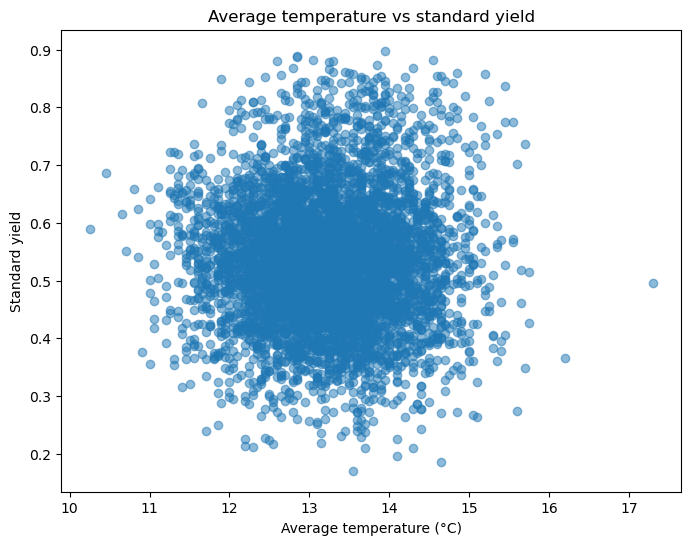

In [4]:
plt.figure(figsize=(8, 6))
plt.scatter(dataset["Ave_temps"], dataset["Standard_yield"], alpha=0.5)
plt.xlabel("Average temperature (°C)")
plt.ylabel("Standard yield")
plt.title("Average temperature vs standard yield")
plt.show()

To put a number on the relationship, I calculate the Pearson correlation coefficient. It ranges from -1 (perfect negative line) through 0 (no linear relationship) to +1 (perfect positive line).

In [5]:
def get_correlation(df, col1, col2):
    """Return the Pearson correlation coefficient between two columns of a DataFrame."""
    correlation, _ = pearsonr(df[col1], df[col2])
    return float(correlation)


temp_correlation = get_correlation(dataset, 'Ave_temps', 'Standard_yield')
print("Pearson correlation (Ave_temps vs Standard_yield):", temp_correlation)

Pearson correlation (Ave_temps vs Standard_yield): 0.006785950289020185


**What the plot and correlation show**

- There is no visible trend. The points form a dense cloud instead of rising or falling along a line.
- The correlation is about 0.007, which is essentially zero.
- At almost every temperature, yields cover a wide range, so temperature alone cannot explain the differences in yield.

Average temperature is not a useful predictor for a linear model.

## 5. Does pollution predict yield?

Next I try `Pollution_level`. I fit a simple linear regression model, plot the line of best fit, and check the correlation.

In [6]:
def fit_linear_regression_model(df, pollution_col, yield_col):
    """
    Fit a simple linear regression of yield on pollution level.

    Returns the fitted model, its predictions, and the actual yield values.
    """
    X = df[[pollution_col]]   # scikit-learn expects a 2D feature array
    y = df[yield_col]

    model = LinearRegression()
    model.fit(X, y)
    predictions = model.predict(X)

    return model, predictions, y


model, predictions, y_values = fit_linear_regression_model(dataset, 'Pollution_level', 'Standard_yield')
print(model)

LinearRegression()


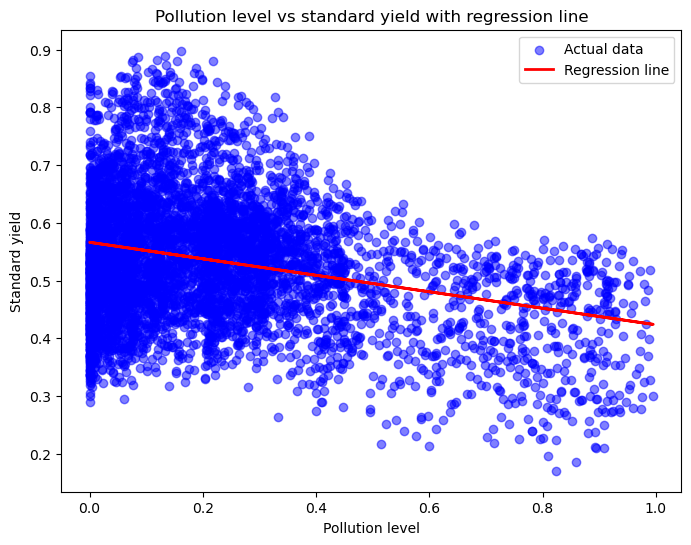

In [7]:
X = dataset[['Pollution_level']]
y = dataset['Standard_yield']

plt.figure(figsize=(8, 6))
plt.scatter(X, y, color='blue', alpha=0.5, label='Actual data')
plt.plot(X, predictions, color='red', linewidth=2, label='Regression line')
plt.xlabel("Pollution level")
plt.ylabel("Standard yield")
plt.title("Pollution level vs standard yield with regression line")
plt.legend()
plt.show()

In [8]:
pollution_correlation = get_correlation(dataset, 'Pollution_level', 'Standard_yield')
print("Pearson correlation (Pollution_level vs Standard_yield):", pollution_correlation)

Pearson correlation (Pollution_level vs Standard_yield): -0.2857609646210545


**What this shows**

The correlation is about -0.29. That is a weak negative relationship: fields with higher pollution tend to have slightly lower yields, but the points are still widely scattered around the line. It is a clearer pattern than temperature (0.007), but far from a strong one.

### Slope and intercept

The slope tells us how much predicted yield changes for each 1-unit increase in pollution. The intercept is the predicted yield when pollution is zero.

In [9]:
def get_slope_intercept(model):
    """Return the slope and intercept of a fitted LinearRegression model."""
    slope = model.coef_[0]
    intercept = model.intercept_
    return slope, intercept


slope, intercept = get_slope_intercept(model)
print("Slope:", slope)
print("Intercept:", intercept)

Slope: -0.14276177209866078
Intercept: 0.566268441539338


- **Slope (about -0.143):** each 1-unit increase in pollution lowers predicted standard yield by about 0.143. Pollution runs from 0 to 1, so going from the cleanest to the most polluted field lowers predicted yield by roughly 0.14 in total. Standard yield itself ranges from about 0.17 to 0.90, so this is a modest effect.
- **Intercept (about 0.566):** the model predicts a standard yield of about 0.57 for a field with no pollution.

## 6. How good is the model?

I measure the model with four metrics:

- **R²:** the share of the variation in yield that the model explains.
- **MAE:** the average size of the prediction error.
- **MSE:** the average squared error (penalises large errors more).
- **RMSE:** the square root of MSE, in the same units as yield.

In [10]:
def calculate_evaluation_metrics(predictions, y_values):
    """Return R-squared, MAE, MSE and RMSE for a set of predictions."""
    r2 = r2_score(y_values, predictions)
    mae = mean_absolute_error(y_values, predictions)
    mse = mean_squared_error(y_values, predictions)
    rmse = np.sqrt(mse)
    return r2, mae, mse, rmse


r2, mae, mse, rmse = calculate_evaluation_metrics(predictions, y_values)
print(f"R-squared: {r2:.4f}")
print(f"MAE:       {mae:.4f}")
print(f"MSE:       {mse:.4f}")
print(f"RMSE:      {rmse:.4f}")
print(f"\nFor comparison, the standard deviation of Standard_yield is {y_values.std():.4f}")

R-squared: 0.0817
MAE:       0.0855
MSE:       0.0115
RMSE:      0.1071

For comparison, the standard deviation of Standard_yield is 0.1118


**What the metrics show**

- **R² = 0.082:** pollution explains only about 8% of the variation in yield. The other 92% comes from other factors.
- **MAE = 0.086:** on average, predictions are off by about 0.09 on a yield scale where the average field is around 0.53.
- **RMSE = 0.107:** this is very close to the standard deviation of yield itself (about 0.112). In other words, predicting with this model is only slightly better than guessing the average yield for every field.

Pollution alone is a weak predictor. To improve the model, other features such as soil fertility, rainfall, slope and crop type should be added.

## 7. Train-test split

The metrics above were calculated on the same data the model was trained on, which can make a model look better than it is. A train-test split fixes this: the model learns from 80% of the fields and is then scored on the 20% it has never seen.

In [11]:
def data_train_test_split(df, pollution_col, yield_col):
    """Split the data 80/20 into training and testing sets."""
    X = df[[pollution_col]]
    y = df[yield_col]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    return X_train, X_test, y_train, y_test


def train_split_linear_regression_model(X_train, X_test, y_train, y_test):
    """Train on the training set and predict on the test set."""
    model = LinearRegression()
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    return model, predictions, y_test


X_train, X_test, y_train, y_test = data_train_test_split(dataset, 'Pollution_level', 'Standard_yield')
print(f"Training set: {X_train.shape[0]} fields | Test set: {X_test.shape[0]} fields")

train_test_model, predictions_test, y_test_actual = train_split_linear_regression_model(X_train, X_test, y_train, y_test)

r2_test, mae_test, mse_test, rmse_test = calculate_evaluation_metrics(predictions_test, y_test_actual)
print(f"\nR-squared (test set): {r2_test:.4f}")
print(f"MAE (test set):       {mae_test:.4f}")
print(f"MSE (test set):       {mse_test:.4f}")
print(f"RMSE (test set):      {rmse_test:.4f}")

Training set: 4523 fields | Test set: 1131 fields

R-squared (test set): 0.0807
MAE (test set):       0.0879
MSE (test set):       0.0123
RMSE (test set):      0.1107


**Comparison**

| Metric | All data | Test set |
|---|---|---|
| R² | 0.082 | 0.081 |
| MAE | 0.086 | 0.088 |
| MSE | 0.0115 | 0.0123 |
| RMSE | 0.107 | 0.111 |

The test-set results are slightly worse, which is expected: the model is now predicting fields it has not seen. The test-set numbers are the more honest measure of how the model would perform on new fields, so they are the ones to trust.

The gap is very small, which tells us the model is not overfitting. That is what we would expect from a model with one feature. The low R² is not caused by overfitting; it is because pollution alone explains little of the yield.

## 8. Residual analysis

Good metrics are not enough on their own. Linear regression also assumes that the residuals (actual yield minus predicted yield) are roughly normally distributed, centred on zero, and have a similar spread across all predictions. If not, the model may be missing structure in the data. I check this with a histogram and a residuals-vs-predictions plot.

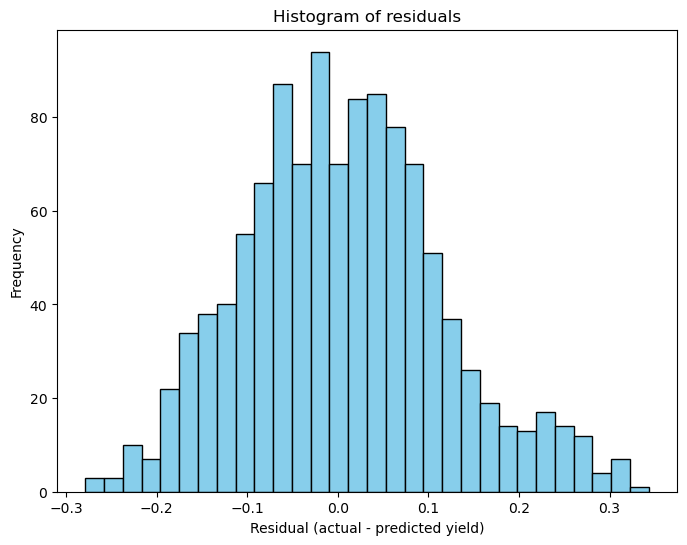

In [12]:
residuals = y_test_actual - predictions_test

plt.figure(figsize=(8, 6))
plt.hist(residuals, bins=30, color='skyblue', edgecolor='black')
plt.xlabel("Residual (actual - predicted yield)")
plt.ylabel("Frequency")
plt.title("Histogram of residuals")
plt.show()

**Histogram**

- The residuals are roughly bell-shaped and centred close to zero, so the model does not systematically over- or under-predict.
- There is a slight right skew: a small number of fields have actual yields noticeably higher than predicted.
- The right tail is longer than the left: a few fields have actual yields well above the prediction (up to about +0.34), while the largest under-shoot is about -0.28.

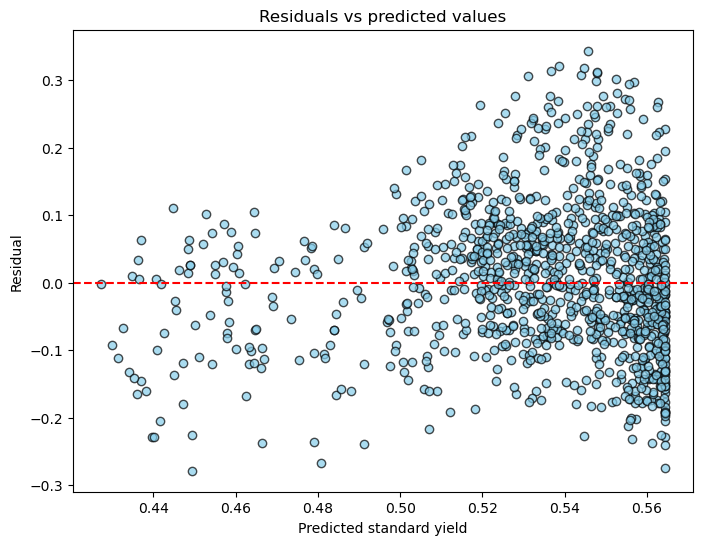

In [13]:
plt.figure(figsize=(8, 6))
plt.scatter(predictions_test, residuals, color='skyblue', edgecolor='black', alpha=0.7)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel("Predicted standard yield")
plt.ylabel("Residual")
plt.title("Residuals vs predicted values")
plt.show()

**Residuals vs predicted values**

- **Spread is not constant.** At low predicted yields (left side) the residuals sit in a fairly narrow band. At high predicted yields (right side) they fan out, from about -0.28 to +0.34. This is heteroscedasticity, which breaks the constant-variance assumption of linear regression.
- **Most fields sit on the right.** Predictions are packed between about 0.52 and 0.565, because most fields have low pollution. The model gives almost the same answer for most fields, which is why it separates them so poorly.
- **No strong overall bias.** Residuals are spread on both sides of zero, but the larger positive residuals at the top confirm the right skew seen in the histogram.
- **What this means:** the pattern suggests something other than pollution is driving yield (for example crop type, which the model ignores). A single-feature linear model only partly fits this data.

### Residual statistics

In [14]:
def calculate_residuals_statistics(predictions, y_test):
    """Return the mean and standard deviation of the residuals."""
    residuals = y_test - predictions
    return np.mean(residuals), np.std(residuals)


mean_residual, std_residual = calculate_residuals_statistics(predictions_test, y_test_actual)
print(f"Mean of residuals:               {mean_residual:.4f}")
print(f"Standard deviation of residuals: {std_residual:.4f}")

Mean of residuals:               0.0059
Standard deviation of residuals: 0.1105


- **Mean = 0.006:** very close to zero, so on average the model neither over- nor under-predicts. The model is not biased.
- **Standard deviation = 0.111:** this shows how much individual predictions vary around the truth. For roughly normal residuals, about 95% of predictions would fall within about ±0.22 of the actual yield. Yields average about 0.53 and have their own standard deviation of about 0.112, so an error this large means the model cannot be relied on for decisions about individual fields.

## 9. Conclusion

- **Temperature** has almost no linear relationship with yield (correlation about 0.007).
- **Pollution** has a weak negative relationship with yield (correlation about -0.29). Higher pollution goes with slightly lower yield.
- **Model performance:** on unseen data the model has an R² of about 0.08 and an RMSE of about 0.11, which is close to the natural spread of yield. The model is unbiased on average but not accurate for individual fields.
- **Residuals** are roughly normal but right-skewed, and their spread grows at higher predictions, so linear regression is only a partial fit here.

**Why this matters:** for farmers and planners in Maji Ndogo, pollution is worth monitoring, but it is not enough by itself to forecast yield.

**Next steps**

1. Build a multiple regression model that adds soil fertility, rainfall, slope, pH and elevation.
2. Split the data by crop type and fit a model for each crop, since different crops respond differently to pollution.
3. Try non-linear models such as decision trees or random forests, and compare them with linear regression using the same test set.